# Lab 08
## GEOG 6890
### Ashtyn Gluck
#### 10/21/2026

## Reading, Exploring and Manipulating Shapefile Data

GeoPandas can read and writite a variety of geospatial data formats, including Shapefiles, GeoJSON, GeoPackage, and more. 

In this lab, We will use the [U.S. Census Bureau TIGER/Line Shapefiles](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.html), which provide geographic boundaries and other spatial features for the United States.

We will begin by exploring Alabama county boundaries, then combine the spatial data with [population statistics](https://data.census.gov/table?q=Alabama+counties) to investigate geographic patterns of population distribution.

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

### 1. Reading shapefiles

In [3]:
counties = gpd.read_file(r"C:\Users\email\OneDrive\Desktop\Auburn\Current_Courses\GEOG_6890\Labs_Homework\Lab8\tl_2026_us_county")

### 2. Exploring shapefiles

In [4]:
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,NaN,37340,NaN,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.613, -80.98674 28.61301..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,NaN,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10364 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,NaN,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,NaN,19700,NaN,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,NaN,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [5]:
counties.columns

Index(['STATEFP', 'COUNTYFP', 'COUNTYNS', 'GEOID', 'GEOIDFQ', 'NAME',
       'NAMELSAD', 'LSAD', 'CLASSFP', 'MTFCC', 'CSAFP', 'CBSAFP', 'METDIVFP',
       'FUNCSTAT', 'ALAND', 'AWATER', 'INTPTLAT', 'INTPTLON', 'geometry'],
      dtype='str')

In [6]:
counties.shape

(3235, 19)

In [7]:
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

In [8]:
counties.geometry

0       POLYGON ((-80.98725 28.613, -80.98674 28.61301...
1       POLYGON ((-122.10363 38.51216, -122.10364 38.5...
2       POLYGON ((-85.31955 39.78736, -85.32016 39.787...
3       POLYGON ((-108.22982 32.20878, -108.22981 32.2...
4       POLYGON ((-75.31622 39.24531, -75.31308 39.241...
                              ...                        
3230    POLYGON ((-104.65564 42.60947, -104.65074 42.6...
3231    POLYGON ((-91.04889 45.29201, -91.04909 45.292...
3232    POLYGON ((-84.74545 37.71562, -84.74501 37.716...
3233    POLYGON ((-92.17907 40.89972, -92.17704 40.899...
3234    POLYGON ((-88.22909 33.89194, -88.2291 33.8918...
Name: geometry, Length: 3235, dtype: geometry

In [9]:
alabama = counties[counties["STATEFP"] == "01"].copy()

In [10]:
alabama

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
179,01,021,00161536,01021,0500000US01021,Chilton,Chilton County,06,H1,G4020,142,13820,NaN,A,1794443227,20587723,+32.8540514,-086.7266071,"POLYGON ((-86.6537 32.70619, -86.66122 32.7061..."
180,01,009,00161530,01009,0500000US01009,Blount,Blount County,06,H1,G4020,142,13820,NaN,A,1670296792,14822587,+33.9773575,-086.5664400,"POLYGON ((-86.56421 33.80194, -86.56556 33.801..."
181,01,073,00161562,01073,0500000US01073,Jefferson,Jefferson County,06,H1,G4020,142,13820,NaN,A,2879038364,32495629,+33.5534439,-086.8965359,"POLYGON ((-86.71061 33.43057, -86.71098 33.430..."
182,01,127,00161589,01127,0500000US01127,Walker,Walker County,06,H1,G4020,142,13820,NaN,A,2048837408,36603375,+33.7915581,-087.3010936,"POLYGON ((-87.19756 33.59123, -87.19752 33.591..."
183,01,007,00161529,01007,0500000US01007,Bibb,Bibb County,06,H1,G4020,142,13820,NaN,A,1612188678,9572300,+33.0158929,-087.1271475,"POLYGON ((-86.87657 33.01891, -86.87657 33.018..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2926,01,133,00161592,01133,0500000US01133,Winston,Winston County,06,H1,G4020,NaN,NaN,NaN,A,1587662808,48868520,+34.1545635,-087.3653509,"POLYGON ((-87.63657 34.12508, -87.63649 34.127..."
3039,01,093,00161573,01093,0500000US01093,Marion,Marion County,06,H1,G4020,NaN,NaN,NaN,A,1922657194,3183478,+34.1376949,-087.8791220,"POLYGON ((-88.20598 34.0688, -88.20582 34.0701..."
3071,01,091,00161572,01091,0500000US01091,Marengo,Marengo County,06,H1,G4020,NaN,NaN,NaN,A,2530155089,14951683,+32.2594744,-087.7908226,"POLYGON ((-87.8053 31.99046, -87.81685 31.9905..."
3142,01,057,00161554,01057,0500000US01057,Fayette,Fayette County,06,H1,G4020,NaN,NaN,NaN,A,1625693258,4330881,+33.7161568,-087.7642923,"POLYGON ((-87.95202 33.88393, -87.952 33.88565..."


<Axes: >

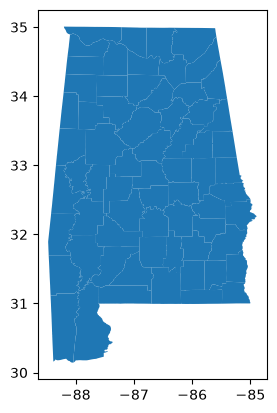

In [11]:
alabama.plot()

In [12]:
alabama.geometry

179     POLYGON ((-86.6537 32.70619, -86.66122 32.7061...
180     POLYGON ((-86.56421 33.80194, -86.56556 33.801...
181     POLYGON ((-86.71061 33.43057, -86.71098 33.430...
182     POLYGON ((-87.19756 33.59123, -87.19752 33.591...
183     POLYGON ((-86.87657 33.01891, -86.87657 33.018...
                              ...                        
2926    POLYGON ((-87.63657 34.12508, -87.63649 34.127...
3039    POLYGON ((-88.20598 34.0688, -88.20582 34.0701...
3071    POLYGON ((-87.8053 31.99046, -87.81685 31.9905...
3142    POLYGON ((-87.95202 33.88393, -87.952 33.88565...
3196    POLYGON ((-87.50262 31.8292, -87.50398 31.8291...
Name: geometry, Length: 67, dtype: geometry

In [13]:
alabama.geometry.area

C:\Users\email\AppData\Local\Temp\ipykernel_17528\2911762884.py:1: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  alabama.geometry.area


179     0.174827
180     0.164405
181     0.282674
182     0.203047
183     0.156472
          ...   
2926    0.159976
3039    0.188230
3071    0.243547
3142    0.158556
3196    0.224266
Length: 67, dtype: float64

### 3. Reproject, then calculate area & centroid

In [14]:
alabama = alabama.to_crs("EPSG:4326")

In [15]:
alabama.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [16]:
alabama.estimate_utm_crs()

<Projected CRS: EPSG:32616>
Name: WGS 84 / UTM zone 16N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 90°W and 84°W, northern hemisphere between equator and 84°N, onshore and offshore. Belize. Canada - Manitoba; Nunavut; Ontario. Costa Rica. Cuba. Ecuador - Galapagos. El Salvador. Guatemala. Honduras. Mexico. Nicaragua. United States (USA).
- bounds: (-90.0, 0.0, -84.0, 84.0)
Coordinate Operation:
- name: UTM zone 16N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [17]:
alabama_projected = alabama.to_crs("EPSG:32616")
alabama_projected.crs

<Projected CRS: EPSG:32616>
Name: WGS 84 / UTM zone 16N
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: Between 90°W and 84°W, northern hemisphere between equator and 84°N, onshore and offshore. Belize. Canada - Manitoba; Nunavut; Ontario. Costa Rica. Cuba. Ecuador - Galapagos. El Salvador. Guatemala. Honduras. Mexico. Nicaragua. United States (USA).
- bounds: (-90.0, 0.0, -84.0, 84.0)
Coordinate Operation:
- name: UTM zone 16N
- method: Transverse Mercator
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [18]:
alabama_projected.geometry.area #square meters

179     1.813621e+09
180     1.683847e+09
181     2.909233e+09
182     2.083818e+09
183     1.620479e+09
            ...     
2926    1.635277e+09
3039    1.924624e+09
3071    2.543431e+09
3142    1.628909e+09
3196    2.348331e+09
Length: 67, dtype: float64

In [19]:
#calculate area in square kilometers
alabama_projected["Area_km2"] = (
    alabama_projected.geometry.area / 1_000_000
)

alabama_projected[["NAME", "Area_km2"]]

,NAME,Area_km2
179,Chilton,1813.620950
180,Blount,1683.847119
181,Jefferson,2909.232571
182,Walker,2083.818358
183,Bibb,1620.478648
...,...,...
2926,Winston,1635.277362
3039,Marion,1924.624106
3071,Marengo,2543.430705
3142,Fayette,1628.908625


In [20]:
#Calculate the centroid of each county
alabama_projected["centroid"] = alabama_projected.geometry.centroid
alabama_projected[["NAME", "centroid"]]

,NAME,centroid
179,Chilton,POINT (526308.235 3634449.257)
180,Blount,POINT (539946.444 3760111.843)
181,Jefferson,POINT (509593.842 3712737.961)
182,Walker,POINT (472485.408 3740383.512)
183,Bibb,POINT (488186.276 3651138.686)
...,...,...
2926,Winston,POINT (465551.647 3778765.167)
3039,Marion,POINT (418212.842 3777648.001)
3071,Marengo,POINT (425616.39 3568138.741)
3142,Fayette,POINT (431545.832 3731483.001)


### 4. Visualize county boundaries and centroids

<Axes: >

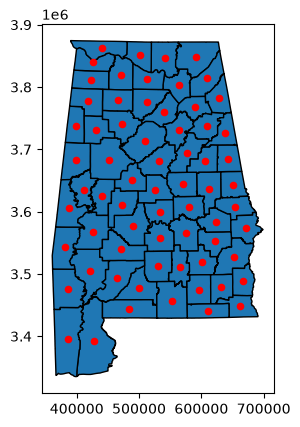

In [21]:
ax = alabama_projected.plot(
    edgecolor = "black"
)

alabama_projected["centroid"].plot(
    ax = ax,
    color = "red",
    marker = "o",
    markersize = 20
)

<Axes: >

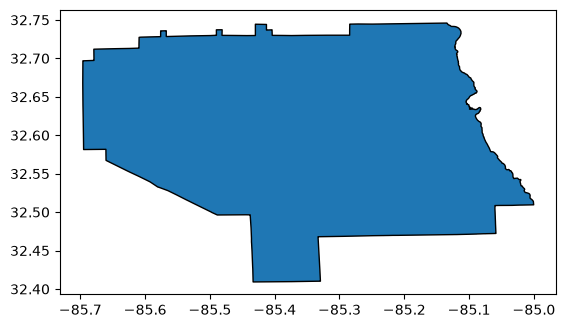

In [22]:
lee = alabama[alabama["NAME"] == "Lee"]
lee
lee.plot(
    edgecolor = "black"
)

### 5. Read the Population Data

In [23]:
population = pd.read_csv(
    r"C:\Users\email\OneDrive\Desktop\Auburn\Current_Courses\GEOG_6890\Labs_Homework\Lab8\Population\DECENNIALPL2020.P1-Data.csv",
    dtype = {"GEO_ID": str}
)

In [24]:
population.head()

,GEO_ID,NAME,P1_001N,P1_002N,P1_003N,P1_004N,P1_005N,P1_006N,P1_007N,P1_008N,...,P1_063N,P1_064N,P1_065N,P1_066N,P1_067N,P1_068N,P1_069N,P1_070N,P1_071N,Unnamed: 73
0,Geography,Geographic Area Name,!!Total:,!!Total:!!Population of one race:,!!Total:!!Population of one race:!!White alone,!!Total:!!Population of one race:!!Black or A...,!!Total:!!Population of one race:!!American I...,!!Total:!!Population of one race:!!Asian alone,!!Total:!!Population of one race:!!Native Haw...,!!Total:!!Population of one race:!!Some Other...,...,!!Total:!!Population of two or more races:!!P...,!!Total:!!Population of two or more races:!!P...,!!Total:!!Population of two or more races:!!P...,!!Total:!!Population of two or more races:!!P...,!!Total:!!Population of two or more races:!!P...,!!Total:!!Population of two or more races:!!P...,!!Total:!!Population of two or more races:!!P...,!!Total:!!Population of two or more races:!!P...,!!Total:!!Population of two or more races:!!P...,NaN
1,0500000US01001,"Autauga County, Alabama",58805,55648,42160,11445,217,881,35,910,...,2,2,0,0,0,0,0,0,0,NaN
2,0500000US01003,"Baldwin County, Alabama",231767,216743,189399,18217,1582,2067,143,5335,...,0,0,0,0,0,0,0,0,0,NaN
3,0500000US01005,"Barbour County, Alabama",25223,24523,11317,11933,116,117,1,1039,...,2,2,0,0,0,0,0,0,0,NaN
4,0500000US01007,"Bibb County, Alabama",22293,21534,16555,4413,60,32,9,465,...,0,0,0,0,0,0,0,0,0,NaN


In [25]:
#Remove the first row containing descriptions
population = population.iloc[1:].copy() #Selects all rows starting from the second row

#Create a five-digit county GEOID
population["GEOID"] = population["GEO_ID"].str[-5:] #Extracts the last five characters of each county

#Rename the total population column
population = population.rename(
    columns = {"P1_001N": "Population"}
)

#Convert population to numeric
population["Population"] = pd.to_numeric(
    population["Population"]
)

#Select relevent columns
population = population[["GEOID", "NAME", "Population"]] #outside brackets mean I group these three columns to a new dataframe

population.head()

,GEOID,NAME,Population
1,01001,"Autauga County, Alabama",58805
2,01003,"Baldwin County, Alabama",231767
3,01005,"Barbour County, Alabama",25223
4,01007,"Bibb County, Alabama",22293
5,01009,"Blount County, Alabama",59134


### 6. Join Population Data to county boundaries

In [26]:
#Join using GEOID
alabama_pop = alabama_projected.merge(
    population[["GEOID", "Population"]], 
    on = "GEOID",
    how = "left", #Keeps all counties from alabama_projected, even if population data is missing
    validate = "one_to_one" #Checks that each GEOID appears at most once in each dataset
)

In [27]:
alabama_pop.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,...,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry,Area_km2,centroid,Population
0,01,021,00161536,01021,0500000US01021,Chilton,Chilton County,06,H1,G4020,...,NaN,A,1794443227,20587723,+32.8540514,-086.7266071,"POLYGON ((532457.378 3618768.29, 531751.835 36...",1813.620950,POINT (526308.235 3634449.257),45014
1,01,009,00161530,01009,0500000US01009,Blount,Blount County,06,H1,G4020,...,NaN,A,1670296792,14822587,+33.9773575,-086.5664400,"POLYGON ((540337.738 3740280.669, 540212.311 3...",1683.847119,POINT (539946.444 3760111.843),59134
2,01,073,00161562,01073,0500000US01073,Jefferson,Jefferson County,06,H1,G4020,...,NaN,A,2879038364,32495629,+33.5534439,-086.8965359,"POLYGON ((526901.399 3699058.907, 526866.908 3...",2909.232571,POINT (509593.842 3712737.961),674721
3,01,127,00161589,01127,0500000US01127,Walker,Walker County,06,H1,G4020,...,NaN,A,2048837408,36603375,+33.7915581,-087.3010936,"POLYGON ((481669.207 3716851.416, 481672.685 3...",2083.818358,POINT (472485.408 3740383.512),65342
4,01,007,00161529,01007,0500000US01007,Bibb,Bibb County,06,H1,G4020,...,NaN,A,1612188678,9572300,+33.0158929,-087.1271475,"POLYGON ((511528.042 3653390.079, 511528.061 3...",1620.478648,POINT (488186.276 3651138.686),22293


In [28]:
alabama_pop[["NAME", "GEOID", "Population", "geometry"]]

,NAME,GEOID,Population,geometry
0,Chilton,01021,45014,"POLYGON ((532457.378 3618768.29, 531751.835 36..."
1,Blount,01009,59134,"POLYGON ((540337.738 3740280.669, 540212.311 3..."
2,Jefferson,01073,674721,"POLYGON ((526901.399 3699058.907, 526866.908 3..."
3,Walker,01127,65342,"POLYGON ((481669.207 3716851.416, 481672.685 3..."
4,Bibb,01007,22293,"POLYGON ((511528.042 3653390.079, 511528.061 3..."
...,...,...,...,...
62,Winston,01133,23540,"POLYGON ((441299.658 3776207.417, 441308.303 3..."
63,Marion,01093,29341,"POLYGON ((388717.249 3770440.206, 388733.256 3..."
64,Marengo,01091,19323,"POLYGON ((423926.477 3539660.69, 422834.947 35..."
65,Fayette,01057,16321,"POLYGON ((411962.527 3749693.956, 411965.403 3..."


### 7. Find the most densely populated counties

In [29]:
#1. Calculate population denisty
alabama_pop["Pop_Density"] = (
    alabama_pop["Population"]/alabama_pop["Area_km2"]
)
alabama_pop

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,...,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry,Area_km2,centroid,Population,Pop_Density
0,01,021,00161536,01021,0500000US01021,Chilton,Chilton County,06,H1,G4020,...,A,1794443227,20587723,+32.8540514,-086.7266071,"POLYGON ((532457.378 3618768.29, 531751.835 36...",1813.620950,POINT (526308.235 3634449.257),45014,24.819960
1,01,009,00161530,01009,0500000US01009,Blount,Blount County,06,H1,G4020,...,A,1670296792,14822587,+33.9773575,-086.5664400,"POLYGON ((540337.738 3740280.669, 540212.311 3...",1683.847119,POINT (539946.444 3760111.843),59134,35.118390
2,01,073,00161562,01073,0500000US01073,Jefferson,Jefferson County,06,H1,G4020,...,A,2879038364,32495629,+33.5534439,-086.8965359,"POLYGON ((526901.399 3699058.907, 526866.908 3...",2909.232571,POINT (509593.842 3712737.961),674721,231.924050
3,01,127,00161589,01127,0500000US01127,Walker,Walker County,06,H1,G4020,...,A,2048837408,36603375,+33.7915581,-087.3010936,"POLYGON ((481669.207 3716851.416, 481672.685 3...",2083.818358,POINT (472485.408 3740383.512),65342,31.356860
4,01,007,00161529,01007,0500000US01007,Bibb,Bibb County,06,H1,G4020,...,A,1612188678,9572300,+33.0158929,-087.1271475,"POLYGON ((511528.042 3653390.079, 511528.061 3...",1620.478648,POINT (488186.276 3651138.686),22293,13.757046
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62,01,133,00161592,01133,0500000US01133,Winston,Winston County,06,H1,G4020,...,A,1587662808,48868520,+34.1545635,-087.3653509,"POLYGON ((441299.658 3776207.417, 441308.303 3...",1635.277362,POINT (465551.647 3778765.167),23540,14.395112
63,01,093,00161573,01093,0500000US01093,Marion,Marion County,06,H1,G4020,...,A,1922657194,3183478,+34.1376949,-087.8791220,"POLYGON ((388717.249 3770440.206, 388733.256 3...",1924.624106,POINT (418212.842 3777648.001),29341,15.245055
64,01,091,00161572,01091,0500000US01091,Marengo,Marengo County,06,H1,G4020,...,A,2530155089,14951683,+32.2594744,-087.7908226,"POLYGON ((423926.477 3539660.69, 422834.947 35...",2543.430705,POINT (425616.39 3568138.741),19323,7.597219
65,01,057,00161554,01057,0500000US01057,Fayette,Fayette County,06,H1,G4020,...,A,1625693258,4330881,+33.7161568,-087.7642923,"POLYGON ((411962.527 3749693.956, 411965.403 3...",1628.908625,POINT (431545.832 3731483.001),16321,10.019592


In [30]:
#2. Find the most densely populated counties
alabama_pop[
    ["NAME", "Pop_Density"]
].sort_values(
    by="Pop_Density",
    ascending = False
).head(10)
        

,NAME,Pop_Density
2,Jefferson,231.924050
18,Madison,184.541123
21,Montgomery,110.584853
28,Lee,109.261687
5,Shelby,106.457870
17,Mobile,97.462646
31,Morgan,79.610683
44,Calhoun,73.465478
43,Etowah,72.837798
33,Houston,71.168797


### 8. Map Population Density

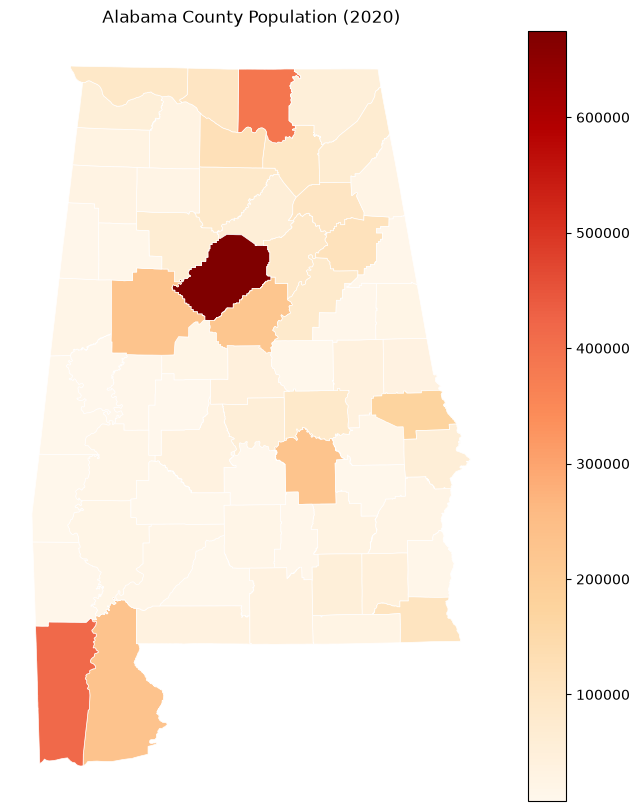

In [31]:
fig, ax = plt.subplots(figsize=(9, 10))

alabama_pop.plot(
    column = "Population",
    ax=ax,
    cmap = "OrRd",
    legend = True,
    edgecolor = "white",
    linewidth = 0.5
)

ax.set_title("Alabama County Population (2020)")
ax.set_axis_off()

plt.show()

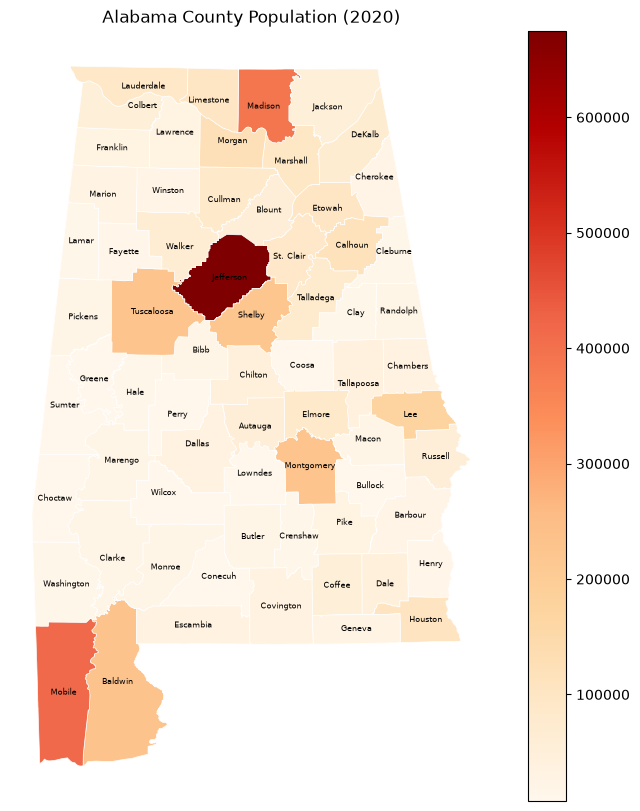

In [34]:
fig, ax = plt.subplots(figsize=(9, 10))

alabama_pop.plot(
    column = "Population",
    ax=ax,
    cmap = "OrRd",
    legend = True,
    edgecolor = "white",
    linewidth = 0.5
)

ax.set_title("Alabama County Population (2020)")
ax.set_axis_off()

for idx, row in alabama_pop.iterrows():
    centroid = row.geometry.representative_point()

    ax.annotate(
        row["NAME"],
        (centroid.x, centroid.y),
        fontsize = 6,
        ha = "center",
        va = "center",
        color = "black"
    )

plt.show()